# Классификация Lenta.ru: TF-IDF, BM25 и CatBoost

Предсказать рубрику новости и сравнить два подхода: собственное TF-IDF-представление текста и классификацию по соседям из поискового индекса.

Первый метод — лемматизация pymorphy3, собственный TF-IDF и LogisticRegression. Второй — три отдельных Lucene BM25-индекса по заголовку, тексту и тегам. Темы и оценки 20 соседей каждого поля образуют 120 признаков для CatBoost.

Lenta.ru: 800 975 строк CSV, из которых 738 973 имеют рубрику. BM25 reference-корпус содержит 618 518 новостей, CatBoost train — 68 725, test — 51 730. TF-IDF обучается на полной train-части с непустыми текстами; словарь содержит 583 280 терминов.

Весь основной код находится в этом ноутбуке. Параметры и пути задаются в начале; результаты сохраняются в `artifacts/full/`.

In [1]:
from __future__ import annotations
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
import json
import hashlib
import joblib
import importlib.util
from types import SimpleNamespace
from sklearn.metrics import accuracy_score
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
import re
from catboost import CatBoostClassifier
from tqdm.auto import tqdm
import jnius_config
import os
from collections import Counter
from collections.abc import Iterable
from typing import ClassVar
from scipy import sparse
from sklearn.base import BaseEstimator
from sklearn.base import TransformerMixin
from sklearn.utils.validation import check_is_fitted
from sklearn.linear_model import LogisticRegression

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", 150)
OUTPUT, LOCAL = Path("artifacts/full"), Path("artifacts/local")
OUTPUT.mkdir(parents=True, exist_ok=True)
LOCAL.mkdir(parents=True, exist_ok=True)
DATA_DIR = Path("data/raw")
if not (DATA_DIR / "lenta-ru-news.csv").exists():
    DATA_DIR = Path.cwd().parents[1] / "restart2"


def save_json(name, value):
    (OUTPUT / name).write_text(
        json.dumps(value, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
    )

## 1. Данные и разбиение

In [2]:
DATA_PATH = DATA_DIR / "lenta-ru-news.csv"

full_data = pd.read_csv(DATA_PATH, low_memory=False)
full_data = full_data.loc[full_data["topic"].notna()].copy()

X = full_data.drop(columns="topic")
y = full_data["topic"]

topics = y.unique()
topic_to_id = {topic: idx for idx, topic in enumerate(topics)}

print(f"Всего документов: {len(full_data):,}")
print("Топ классов:")
display(y.value_counts().head(10))


def stratified_split_with_rare(
    features: pd.DataFrame,
    target: pd.Series,
    test_size: float = 0.2,
    min_count: int = 2,
    random_state: int = 42,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    """Разделить данные стратифицированно, отправив редкие классы в тест.

    Классы с количеством объектов меньше min_count целиком уйдут в тест.
    Размер теста для остальных классов задаётся параметром test_size.
    """
    counts = target.value_counts()
    rare_classes = counts.index[counts < min_count]

    rare_mask = target.isin(rare_classes).to_numpy()
    indices = np.arange(len(target))

    train_idx, test_idx = train_test_split(
        indices[~rare_mask],
        test_size=test_size,
        stratify=target.iloc[indices[~rare_mask]],
        random_state=random_state,
    )
    test_idx = np.concatenate([test_idx, indices[rare_mask]])

    return (
        features.iloc[train_idx].copy(),
        features.iloc[test_idx].copy(),
        target.iloc[train_idx].copy(),
        target.iloc[test_idx].copy(),
    )


# Отдельная тестовая выборка; всё обучение происходит без неё.
X_train_all, X_test, y_train_all, y_test = stratified_split_with_rare(
    X, y, test_size=0.07, min_count=2, random_state=42
)

# Первый этап учит BM25-индексы, второй — CatBoost на соседях BM25.
X_BM25, X_Catboost, y_BM25, y_Catboost = stratified_split_with_rare(
    X_train_all, y_train_all, test_size=0.1, min_count=2, random_state=42
)

print(f"BM25: {len(X_BM25):,}, CatBoost: {len(X_Catboost):,}, Test: {len(X_test):,}")
input_counts = {
    "source_rows": len(pd.read_csv(DATA_PATH, usecols=["topic"])),
    "labelled_rows": len(full_data),
    "reference_rows": len(X_BM25),
    "catboost_train_rows": len(X_Catboost),
    "test_rows": len(X_test),
}
assert len(X_BM25) + len(X_Catboost) + len(X_test) == len(full_data)
assert set(X_train_all.index).isdisjoint(X_test.index)
save_json("input_counts.json", input_counts)
split_hash = hashlib.sha256(
    np.concatenate([X_BM25.index, X_Catboost.index, X_test.index])
    .astype("int64")
    .tobytes()
).hexdigest()
save_json(
    "config.json",
    {
        "source": "TFIDF_BM25_Windows_refactored (1).ipynb",
        "seed": 42,
        "test_fraction": 0.07,
        "reference_fraction_of_train": 0.9,
        "split_sha256": split_hash,
        "bm25_k": 20,
        "k1": 1.2,
        "b": 0.75,
    },
)

Всего документов: 738,973
Топ классов:


topic
Россия             160445
Мир                136621
Экономика           79528
Спорт               64413
Культура            53797
Бывший СССР         53402
Наука и техника     53136
Интернет и СМИ      44663
Из жизни            27605
Дом                 21734
Name: count, dtype: int64

BM25: 618,518, CatBoost: 68,725, Test: 51,730


## 2. Индексы Lucene BM25

Java-классы Anserini вызываются через PyJNIus. Сохранённые индексы открываются для чтения; при их отсутствии строятся полные локальные индексы. Нужна Java 21+.

In [3]:
package = Path(importlib.util.find_spec("pyserini").origin).parent
jars = list((package / "resources/jars").glob("anserini-*-fatjar.jar"))
assert jars, "Install pyserini with its Anserini JAR"
jnius_config.add_classpath(str(jars[0]))
from jnius import autoclass  # noqa: E402 - JVM classpath must be configured first  # noqa: E402 - JVM classpath must be configured first  # noqa: E402 - JVM classpath must be configured first

JSearcher = autoclass("io.anserini.search.SimpleSearcher")
JAnalyzer = autoclass("org.apache.lucene.analysis.core.WhitespaceAnalyzer")
JList = autoclass("java.util.ArrayList")


class LuceneSearcher:
    def __init__(self, index_path):
        self.object = JSearcher(str(Path(index_path).resolve()))
        self.num_docs = self.object.get_total_num_docs()
        self.object.set_analyzer(JAnalyzer())
        self.object.set_bm25(1.2, 0.75)

    def batch_search(self, queries, qids, k=20, threads=8):
        jq, ji = JList(), JList()
        for q, i in zip(queries, qids):
            jq.add(q)
            ji.add(i)
        result = self.object.batch_search(jq, ji, int(k), int(threads))
        return {
            i: [
                SimpleNamespace(docid=h.docid, score=float(h.score))
                for h in result.get(i)
            ]
            for i in qids
            if result.containsKey(i)
        }


def tokenize(text):
    return (
        " ".join(re.findall(r"\w+", text.casefold())) if isinstance(text, str) else None
    )


def create_retriever(series, index_path, k1=1.2, b=0.75):
    original = DATA_DIR / "indexes" / Path(index_path).name
    local = LOCAL / "indexes" / Path(index_path).name
    path = original if original.exists() else local
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        JIndexer = autoclass("io.anserini.index.SimpleIndexer")
        JDoc = autoclass("io.anserini.collection.JsonCollection$Document")
        indexer = JIndexer(
            [
                "-index",
                str(path.resolve()),
                "-pretokenized",
                "-input",
                "",
                "-collection",
                "JsonCollection",
                "-threads",
                "4",
            ]
        )
        for start in range(0, len(series), 5000):
            documents = [
                JDoc.fromFields(str(i), text)
                for i, text in enumerate(series.iloc[start : start + 5000], start)
            ]
            indexer.addJsonDocuments(documents)
        indexer.close()
    searcher = LuceneSearcher(path)
    assert searcher.num_docs == len(series), (path.name, searcher.num_docs, len(series))
    print(path.name, "full indexed rows:", searcher.num_docs, flush=True)
    return searcher

In [4]:
BM25_FIELDS = ("title", "text", "tags")
BM25_K = 20

retrievers = {}

for field in BM25_FIELDS:
    # У каждого поля — свой индекс; иначе индексы конфликтуют по пути.
    corpus = X_BM25[field].dropna().map(tokenize)
    retrievers[field] = create_retriever(
        series=corpus,
        index_path=str(Path("indexes") / f"bm25_{field}"),
    )

print(f"Построено индексов: {len(retrievers)}")

bm25_title full indexed rows: 618518


bm25_text full indexed rows: 618514


bm25_tags full indexed rows: 596506


Построено индексов: 3


## 3. Те же 120 признаков соседей: темы и scores для title, text, tags

In [5]:
def retrieve_bm25_batch_topk(
    documents: pd.DataFrame,
    retriever: LuceneSearcher,
    field: str,
    k: int = 5,
    threads: int = 8,
    batch_size: int = 1_024,
) -> pd.Series:
    """Вернуть для каждого документа список пар (docid, BM25-score)."""
    matches = [[] for _ in range(len(documents))]

    for start in tqdm(range(0, len(documents), batch_size), desc=field):
        end = min(start + batch_size, len(documents))
        batch = [
            (idx, tokenize(value))
            for idx, value in enumerate(documents[field].iloc[start:end], start)
            if isinstance(value, str) and value.strip()
        ]
        batch = [(idx, query) for idx, query in batch if query]
        if not batch:
            continue

        result = retriever.batch_search(
            queries=[query for _, query in batch],
            qids=[str(idx) for idx, _ in batch],
            k=k,
            threads=threads,
        )

        for idx, _ in batch:
            matches[idx] = [
                (int(hit.docid), float(hit.score)) for hit in result.get(str(idx), [])
            ]

    return pd.Series(matches, index=documents.index, name=f"{field}_topk")


def add_bm25_neighbor_features(
    data: pd.DataFrame,
    reference_data: pd.DataFrame,
    reference_target: pd.Series,
    retrievers: dict[str, LuceneSearcher],
    k: int = 20,
) -> tuple[pd.DataFrame, list[str]]:
    """Добавить темы и scores ближайших соседей без изменения оригинала."""
    result = data.copy()
    feature_names = []

    for field, retriever in retrievers.items():
        hits = retrieve_bm25_batch_topk(
            documents=data,
            retriever=retriever,
            field=field,
            k=k,
            threads=8,
        )
        # Нумерация docid соответствует только непустым строкам поля.
        valid_positions = np.flatnonzero(reference_data[field].notna().to_numpy())
        reference_topics = reference_target.iloc[valid_positions].to_numpy()

        for rank in range(k):
            topic_col = f"{field}_{rank + 1}_topic"
            score_col = f"{field}_{rank + 1}_score"

            result[topic_col] = [
                reference_topics[row[rank][0]] if len(row) > rank else None
                for row in hits
            ]
            result[score_col] = [
                row[rank][1] if len(row) > rank else np.nan for row in hits
            ]
            feature_names.extend((topic_col, score_col))

    return result, feature_names

In [6]:
feature_cache = LOCAL / ("lucene_neighbors_" + split_hash[:16] + ".joblib")
if feature_cache.exists():
    X_catboost_features, X_test_bm25, feature_names = joblib.load(feature_cache)
else:
    X_catboost_features, feature_names = add_bm25_neighbor_features(
        data=X_Catboost,
        reference_data=X_BM25,
        reference_target=y_BM25,
        retrievers=retrievers,
        k=BM25_K,
    )

    X_test_bm25, _ = add_bm25_neighbor_features(
        data=X_test,
        reference_data=X_BM25,
        reference_target=y_BM25,
        retrievers=retrievers,
        k=BM25_K,
    )

    X_catboost_features = X_catboost_features[feature_names].copy()
    X_test_bm25 = X_test_bm25[feature_names].copy()
    joblib.dump(
        (X_catboost_features, X_test_bm25, feature_names), feature_cache, compress=3
    )
# Явно разделяем категориальные и числовые признаки.
cat_features = list(
    X_catboost_features[feature_names]
    .select_dtypes(include=["object", "string", "category"])
    .columns
)
num_features = [col for col in feature_names if col not in cat_features]

for frame in (X_catboost_features, X_test_bm25):
    frame[cat_features] = frame[cat_features].fillna("nan")
    frame[num_features] = frame[num_features].fillna(-1.0)

print(f"Категориальных признаков: {len(cat_features)}")
print(f"Числовых признаков: {len(num_features)}")

Категориальных признаков: 60
Числовых признаков: 60


## 4. CatBoost по признакам соседей

In [7]:
catboost_model = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="MultiClass",
    verbose=100,
    thread_count=-1,
    cat_features=cat_features,
    task_type="GPU",
    gpu_ram_part=0.2,
    train_dir=str(LOCAL / "catboost_info"),  # Для запуска без CUDA замените на "CPU".
)

catboost_model.fit(
    X_catboost_features[feature_names],
    y_Catboost.map(topic_to_id),
)

catboost_pred = catboost_model.predict(X_test_bm25[feature_names]).ravel()
catboost_y_true = y_test.map(topic_to_id)


catboost_metrics = {
    "macro": f1_score(catboost_y_true, catboost_pred, average="macro"),
    "micro": f1_score(catboost_y_true, catboost_pred, average="micro"),
    "weighted": f1_score(catboost_y_true, catboost_pred, average="weighted"),
    "acc_macro": accuracy_score(catboost_y_true, catboost_pred),
}
display(pd.Series(catboost_metrics, name="F1, BM25 + CatBoost"))
catboost_model.save_model(str(OUTPUT / "catboost.cbm"))
save_json("catboost_metrics.json", {k: float(v) for k, v in catboost_metrics.items()})
pd.DataFrame(
    {
        "row_id": X_test.index,
        "label": y_test,
        "prediction": [topics[int(i)] for i in catboost_pred],
    }
).to_csv(OUTPUT / "catboost_predictions.csv", index=False)

Learning rate set to 0.153835


0:	learn: 1.6944341	total: 96.3ms	remaining: 1m 36s


100:	learn: 0.3372474	total: 8.02s	remaining: 1m 11s


200:	learn: 0.2806117	total: 15.9s	remaining: 1m 3s


300:	learn: 0.2538760	total: 23.5s	remaining: 54.6s


...

700:	learn: 0.1944835	total: 53.7s	remaining: 22.9s


800:	learn: 0.1826133	total: 1m 1s	remaining: 15.3s


900:	learn: 0.1693065	total: 1m 9s	remaining: 7.6s


999:	learn: 0.1593070	total: 1m 16s	remaining: 0us


macro        0.723403
micro        0.901257
weighted     0.900964
acc_macro    0.901257
Name: F1, BM25 + CatBoost, dtype: float64

## 5. Собственный TF-IDF

Лемматизация pymorphy3, TF=count/length, IDF=log((1+N)/(1+DF)), без дополнительного +1 и L2-нормализации. Полный словарь и LogisticRegression.

In [8]:
"""TF-IDF по собственной формуле с безопасной обработкой текстов в Windows.

TF(t, d) = count(t, d) / len(d)
IDF(t)   = log((1 + N) / (1 + DF(t)))

Зависимости: numpy, pandas, scipy, pymorphy3, pandarallel (если включён).
"""


def _preprocess_document(text: object) -> list[str]:
    """Изолированный Windows-safe worker: на входе только один текст.

    Все зависимости импортируются ВНУТРИ функции (требование Pandarallel
    для Windows/spawn). Морфологический анализатор и LRU-кеш привязаны
    к текущему процессу, поэтому не передаются между процессами.
    """
    import multiprocessing
    import re
    from functools import lru_cache

    if not isinstance(text, str):
        return []

    tokens = re.findall(r"\w+", text.casefold())
    if not tokens:
        return []

    process = multiprocessing.current_process()
    normalize = getattr(process, "_tfidf_ru_normalize", None)

    if normalize is None:
        import pymorphy3

        morph = pymorphy3.MorphAnalyzer(lang="ru")

        @lru_cache(maxsize=100_000)
        def normalize(token: str) -> str:
            return morph.parse(token)[0].normal_form

        # Свой кеш у КАЖДОГО процесса, без общих глобальных переменных.
        process._tfidf_ru_normalize = normalize

    return [normalize(token) for token in tokens]


class TfidfEmbedder(BaseEstimator, TransformerMixin):
    """Строит разреженные TF-IDF-эмбеддинги русскоязычных документов.

    В отличие от sklearn.TfidfVectorizer сохраняет исходную формулу IDF:
    log((1 + N) / (1 + DF)), без прибавления единицы и L2-нормализации.

    Параметры
    ---------
    n_workers : int | None
        Число процессов Pandarallel. Если None, не более 4 процессов.
    use_pandarallel : bool
        Использовать несколько процессов для токенизации и лемматизации.
    batch_size : int
        Сколько текстов передавать на обработку за один вызов. В Windows
        каждый вызов запускает собственный набор рабочих процессов.
    min_parallel_documents : int
        Малые пакеты обрабатываются последовательно во избежание overhead.
    progress_bar : bool
        Показывать прогресс Pandarallel.

    Примечания
    ----------
    * В обработчик отправляется только независимая копия части Series,
      а НЕ DataFrame целиком, НЕ self и НЕ словарь TF-IDF.
    * Обработчик не обращается к глобальным объектам ноутбука.
    * fit / transform не изменяют входные данные и не используют общие
      изменяемые списки для сборки разреженной матрицы.
    """

    _pandarallel_ready: ClassVar[bool] = False
    _pandarallel_workers: ClassVar[int | None] = None

    def __init__(
        self,
        n_workers: int | None = None,
        use_pandarallel: bool = True,
        batch_size: int = 100_000,
        min_parallel_documents: int = 1_000,
        progress_bar: bool = False,
    ) -> None:
        self.n_workers = n_workers
        self.use_pandarallel = use_pandarallel
        self.batch_size = batch_size
        self.min_parallel_documents = min_parallel_documents
        self.progress_bar = progress_bar

    def _validate_parameters(self) -> int:
        if self.n_workers is not None and self.n_workers < 1:
            raise ValueError("n_workers должен быть положительным числом")
        if self.batch_size < 1:
            raise ValueError("batch_size должен быть положительным числом")
        if self.min_parallel_documents < 1:
            raise ValueError("min_parallel_documents должен быть положительным числом")
        return (
            self.n_workers
            if self.n_workers is not None
            else min(4, os.cpu_count() or 1)
        )

    @classmethod
    def _initialize_pandarallel(cls, workers: int, progress_bar: bool) -> None:
        """Инициализируется только в основном процессе, НЕ при импорте модуля."""
        if cls._pandarallel_ready:
            if cls._pandarallel_workers != workers:
                raise RuntimeError(
                    "Pandarallel уже инициализирован другим числом процессов. "
                    "Используйте то же n_workers или перезапустите ядро."
                )
            return

        from pandarallel import pandarallel

        # На Windows используется передача данных через multiprocessing pipe;
        # /dev/shm отсутствует. Не нужна общая память между процессами.
        pandarallel.initialize(
            nb_workers=workers,
            progress_bar=progress_bar,
            use_memory_fs=False,
            verbose=0,
        )
        cls._pandarallel_workers = workers
        cls._pandarallel_ready = True

    def _iter_documents(self, texts: Iterable[str | None]):
        """Последовательно выдаёт списки лемм без хранения всего корпуса в RAM."""
        workers = self._validate_parameters()

        # Series с индексами из исходного DataFrame не должен попадать в worker:
        # передаём только самостоятельную Series с последовательным индексом.
        data = pd.Series(texts, dtype="object").reset_index(drop=True).copy(deep=True)

        for start in range(0, len(data), self.batch_size):
            payload = (
                data.iloc[start : start + self.batch_size]
                .reset_index(drop=True)
                .copy(deep=True)
            )

            if (
                self.use_pandarallel
                and workers > 1
                and len(payload) >= self.min_parallel_documents
            ):
                self._initialize_pandarallel(workers, self.progress_bar)
                lemmatized = payload.parallel_apply(_preprocess_document)
            else:
                lemmatized = payload.apply(_preprocess_document)

            yield from lemmatized

    def fit(self, texts: Iterable[str | None], y: object = None) -> TfidfEmbedder:
        """Вычислить словарь и IDF по тренировочным документам."""
        vocabulary: dict[str, int] = {}
        doc_freq: list[int] = []
        n_documents = 0

        for tokens in self._iter_documents(texts):
            n_documents += 1
            for term in Counter(tokens):
                column = vocabulary.get(term)
                if column is None:
                    column = len(vocabulary)
                    vocabulary[term] = column
                    doc_freq.append(0)
                doc_freq[column] += 1

        self._save_statistics(vocabulary, doc_freq, n_documents)
        return self

    def fit_transform(
        self, texts: Iterable[str | None], y: object = None, **fit_params: object
    ) -> sparse.csr_matrix:
        """Обучить словарь и сразу построить CSR, без двойной лемматизации.

        TF-части матрицы создаются отдельными разреженными блоками;
        после вычисления DF к ним применяется общий IDF. Поэтому нет
        единого огромного списка всех ненулевых элементов корпуса.
        """
        vocabulary: dict[str, int] = {}
        doc_freq: list[int] = []
        blocks: list[sparse.csr_matrix] = []
        rows: list[int] = []
        cols: list[int] = []
        tfs: list[float] = []
        n_documents = 0
        rows_in_block = 0

        for tokens in self._iter_documents(texts):
            if tokens:
                counts = Counter(tokens)
                length = len(tokens)
                for term, count in counts.items():
                    column = vocabulary.get(term)
                    if column is None:
                        column = len(vocabulary)
                        vocabulary[term] = column
                        doc_freq.append(0)

                    doc_freq[column] += 1
                    rows.append(rows_in_block)
                    cols.append(column)
                    tfs.append(count / length)

            n_documents += 1
            rows_in_block += 1

            if rows_in_block == self.batch_size:
                blocks.append(
                    self._tf_block(rows, cols, tfs, rows_in_block, len(vocabulary))
                )
                rows, cols, tfs = [], [], []
                rows_in_block = 0

        if rows_in_block:
            blocks.append(
                self._tf_block(rows, cols, tfs, rows_in_block, len(vocabulary))
            )

        self._save_statistics(vocabulary, doc_freq, n_documents)

        # Размер словаря рос во время обучения. Выравниваем ширину блоков
        # и умножаем значения только на обученные IDF-веса.
        for block in blocks:
            block.resize((block.shape[0], len(self.vocabulary_)))
            block.data *= self.idf_[block.indices]

        return sparse.vstack(blocks, format="csr")

    def transform(self, texts: Iterable[str | None]) -> sparse.csr_matrix:
        """Применить обученный словарь: неизвестные слова не добавляются."""
        check_is_fitted(self, ["vocabulary_", "idf_", "n_documents_"])

        blocks: list[sparse.csr_matrix] = []
        rows: list[int] = []
        cols: list[int] = []
        tfs: list[float] = []
        rows_in_block = 0

        for tokens in self._iter_documents(texts):
            if tokens:
                counts = Counter(tokens)
                length = len(tokens)  # Включая слова, которых нет в словаре.
                for term, count in counts.items():
                    column = self.vocabulary_.get(term)
                    if column is not None:
                        rows.append(rows_in_block)
                        cols.append(column)
                        tfs.append(count / length)
            rows_in_block += 1

            if rows_in_block == self.batch_size:
                block = self._tf_block(
                    rows, cols, tfs, rows_in_block, len(self.vocabulary_)
                )
                block.data *= self.idf_[block.indices]
                blocks.append(block)
                rows, cols, tfs = [], [], []
                rows_in_block = 0

        if rows_in_block:
            block = self._tf_block(
                rows, cols, tfs, rows_in_block, len(self.vocabulary_)
            )
            block.data *= self.idf_[block.indices]
            blocks.append(block)

        if not blocks:
            return sparse.csr_matrix((0, len(self.vocabulary_)), dtype=np.float64)
        return sparse.vstack(blocks, format="csr")

    def _save_statistics(
        self, vocabulary: dict[str, int], doc_freq: list[int], n_documents: int
    ) -> None:
        if n_documents == 0:
            raise ValueError("Невозможно обучить TF-IDF на пустом корпусе")

        self.vocabulary_ = vocabulary
        self.n_documents_ = n_documents
        self.document_frequency_ = np.asarray(doc_freq, dtype=np.int64)
        self.idf_ = np.log((1.0 + n_documents) / (1.0 + self.document_frequency_))
        self.n_features_in_ = len(vocabulary)

    @staticmethod
    def _tf_block(
        rows: list[int],
        cols: list[int],
        tfs: list[float],
        n_rows: int,
        n_cols: int,
    ) -> sparse.csr_matrix:
        """Собрать локальный TF-блок с минимумом промежуточных копий."""
        return sparse.csr_matrix(
            (
                np.asarray(tfs, dtype=np.float64),
                (
                    np.asarray(rows, dtype=np.int32),
                    np.asarray(cols, dtype=np.int32),
                ),
            ),
            shape=(n_rows, n_cols),
            dtype=np.float64,
        )

In [9]:
# Обучаем TF-IDF только на train, как в оригинальном ноутбуке.
train_mask = X_train_all["text"].notna()
train_texts = X_train_all.loc[train_mask, "text"]
train_labels = y_train_all.loc[train_mask]

tfidf = TfidfEmbedder(
    n_workers=8,  # Разумный старт для Windows (не 16 процессов).
    use_pandarallel=True,
    batch_size=50_000,  # Отдельные порции — меньше пик потребления RAM.
    min_parallel_documents=1_000,
    progress_bar=False,
)

X_train_tfidf = tfidf.fit_transform(train_texts)
X_test_tfidf = tfidf.transform(X_test["text"])

print("TF-IDF train:", X_train_tfidf.shape)
print("TF-IDF test:", X_test_tfidf.shape)
print("Число терминов:", len(tfidf.vocabulary_))

TF-IDF train: (687238, 583280)
TF-IDF test: (51730, 583280)
Число терминов: 583280


In [10]:
logreg = LogisticRegression(max_iter=2000, tol=1e-7)
previous_path = LOCAL / "tfidf_classifier.joblib"
if previous_path.exists():
    previous = joblib.load(previous_path)
    if previous["tfidf"].vocabulary_ == tfidf.vocabulary_ and np.array_equal(
        previous["tfidf"].idf_, tfidf.idf_
    ):
        logreg = previous["classifier"]
        logreg.set_params(max_iter=2000, tol=1e-7, warm_start=True)
        print(
            "Continuing the same full-data C=1 objective to a stricter optimization tolerance",
            flush=True,
        )
with threadpool_limits(limits=8):
    logreg.fit(X_train_tfidf, train_labels)
    tfidf_pred = logreg.predict(X_test_tfidf)
tfidf_metrics = {
    "macro": f1_score(y_test, tfidf_pred, average="macro"),
    "micro": f1_score(y_test, tfidf_pred, average="micro"),
    "weighted": f1_score(y_test, tfidf_pred, average="weighted"),
    "accuracy": accuracy_score(y_test, tfidf_pred),
}
display(pd.Series(tfidf_metrics, name="Original TF-IDF + LogisticRegression"))
joblib.dump(
    {"tfidf": tfidf, "classifier": logreg},
    LOCAL / "tfidf_classifier.joblib",
    compress=3,
)
save_json("tfidf_metrics.json", tfidf_metrics)

Continuing the same full-data C=1 objective to a stricter optimization tolerance


macro       0.524016
micro       0.826619
weighted    0.820818
accuracy    0.826619
Name: Original TF-IDF + LogisticRegression, dtype: float64

## 6. Проверка воспроизведения и артефакты

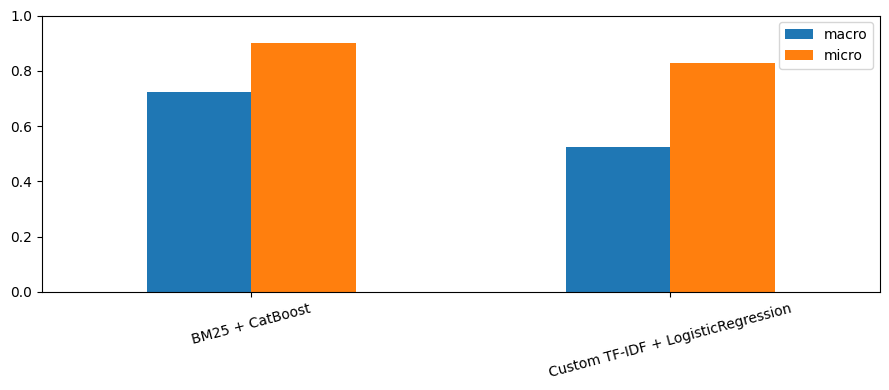

Reference accuracy: 0.901257; measured: 0.9012565242605838
Reference TF-IDF accuracy: 0.826406; measured: 0.8266189831819061


In [11]:
results = {
    "BM25 + CatBoost": {k: float(v) for k, v in catboost_metrics.items()},
    "Custom TF-IDF + LogisticRegression": tfidf_metrics,
}
parity = {
    "reference_catboost_accuracy": 0.9012565242605838,
    "reference_catboost_macro_f1": 0.723403,
    "reference_tfidf_accuracy": 0.826406,
    "reference_tfidf_macro_f1": 0.523546,
    "measured": results,
    "protocol": "Original full-data split and algorithms; Java Lucene, 3 fields, 20 neighbors; LR tolerance tightened to 1e-7",
    "tfidf_optimizer": {
        "C": 1.0,
        "solver": "lbfgs",
        "tol": 1e-7,
        "max_iter": 2000,
        "n_iter": int(logreg.n_iter_[0]),
    },
}
save_json("metrics.json", results)
save_json("parity.json", parity)
pd.DataFrame(results).T[["macro", "micro"]].plot.bar(
    rot=15, ylim=(0, 1), figsize=(9, 4)
)
plt.tight_layout()
plt.savefig(OUTPUT / "comparison.png", dpi=150)
plt.show()
print("Reference accuracy: 0.901257; measured:", catboost_metrics["acc_macro"])
print("Reference TF-IDF accuracy: 0.826406; measured:", tfidf_metrics["accuracy"])